<a href="https://colab.research.google.com/github/berriomelendrezg-tech/Dise-o-experimental/blob/main/Metodo_de_Runge_Kutta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tiempo óptimo (t_opt): 0.1980 horas
Concentración máxima de meta-xileno (CX_max): 0.005067 lbmol/ft^3


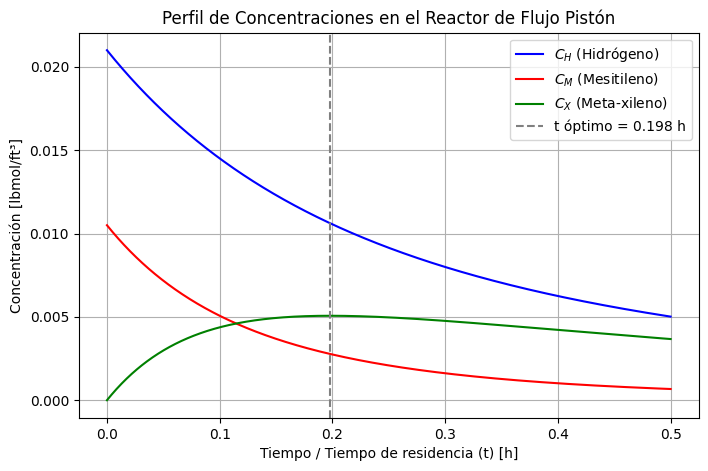

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros cinéticos
k1 = 55.2
k2 = 30.2

# Definición del sistema de EDOs
def f(t, C):
    CH, CM, CX = C
    # Evitar raíces complejas por redondeos numéricos
    CH_val = max(CH, 0)

    dCH_dt = -k1 * (CH_val**0.5) * CM - k2 * (CH_val**0.5) * CX
    dCM_dt = -k1 * (CH_val**0.5) * CM
    dCX_dt = k1 * (CH_val**0.5) * CM - k2 * (CH_val**0.5) * CX
    return np.array([dCH_dt, dCM_dt, dCX_dt])

# Parámetros de la simulación
t0, tf = 0.0, 0.5
n_steps = 1000
h = (tf - t0) / n_steps

t = np.linspace(t0, tf, n_steps + 1)
C = np.zeros((n_steps + 1, 3))
C[0] = [0.021, 0.0105, 0.0]  # Condiciones iniciales [CH, CM, CX]

# Implementación de RK4
for i in range(n_steps):
    k1_vec = h * f(t[i], C[i])
    k2_vec = h * f(t[i] + 0.5*h, C[i] + 0.5*k1_vec)
    k3_vec = h * f(t[i] + 0.5*h, C[i] + 0.5*k2_vec)
    k4_vec = h * f(t[i] + h, C[i] + k3_vec)

    C[i+1] = C[i] + (k1_vec + 2*k2_vec + 2*k3_vec + k4_vec) / 6.0

# Determinación del tiempo óptimo (máximo C_X)
idx_max = np.argmax(C[:, 2])
t_opt = t[idx_max]
CX_max = C[idx_max, 2]

print(f"Tiempo óptimo (t_opt): {t_opt:.4f} horas")
print(f"Concentración máxima de meta-xileno (CX_max): {CX_max:.6f} lbmol/ft^3")

# Graficar
plt.figure(figsize=(8, 5))
plt.plot(t, C[:, 0], label='$C_H$ (Hidrógeno)', color='blue')
plt.plot(t, C[:, 1], label='$C_M$ (Mesitileno)', color='red')
plt.plot(t, C[:, 2], label='$C_X$ (Meta-xileno)', color='green')
plt.axvline(x=t_opt, color='gray', linestyle='--', label=f't óptimo = {t_opt:.3f} h')

plt.title('Perfil de Concentraciones en el Reactor de Flujo Pistón')
plt.xlabel('Tiempo / Tiempo de residencia (t) [h]')
plt.ylabel('Concentración [lbmol/ft³]')
plt.grid(True)
plt.legend()
plt.show()